# Drivix MLDLC — Stage 4: Feature Selection

**Project:** Drivix Smart Parking Dynamic Pricing Engine  
**Objective:** Evaluate feature importance, assess multicollinearity (VIF), and justify final feature retention.  
**Subsystem:** `ml_service`

---

## 1. Feature Selection Strategy
To build an interpretable, resilient production model:
1. **Exclude Target Leakage & Outcomes:**
   - Exclude `policy_quoted_total_inr` and `policy_price_multiplier` to prevent feedback loops.
   - Exclude `outcome_bookingId` and `outcome_status`.
2. **Correlation & Multicollinearity Analysis:**
   - Examine Variance Inflation Factors (VIF) and correlations.
3. **Model-Based Feature Importance:**
   - Train a Random Forest regressor on the training split and inspect MDI (Mean Decrease in Impurity) feature importances.
4. **Permutation Importance:**
   - Measure decrease in validation score when each feature is randomly shuffled.
5. **Final Feature Set Justification.**

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

sys.path.append(os.path.join("..", "src"))
from feature_engineering import get_engineered_feature_names, FEATURE_COLUMNS_RAW

DATA_DIR = os.path.join("..", "data", "processed")
FIG_DIR = os.path.join("..", "reports", "figures")
os.makedirs(FIG_DIR, exist_ok=True)

train_df = pd.read_csv(os.path.join(DATA_DIR, "train_dataset.csv"))
valid_df = pd.read_csv(os.path.join(DATA_DIR, "valid_dataset.csv"))

preprocessor = joblib.load(os.path.join("..", "models", "preprocessor.joblib"))

X_train = preprocessor.transform(train_df[FEATURE_COLUMNS_RAW])
y_train = train_df['y_reserved_occupancy_rate'].values

X_valid = preprocessor.transform(valid_df[FEATURE_COLUMNS_RAW])
y_valid = valid_df['y_reserved_occupancy_rate'].values

feature_names = get_engineered_feature_names(preprocessor)
print(f"Features for evaluation ({len(feature_names)}):", feature_names)

Features for evaluation (18): ['f_capacity', 'f_entry_hour', 'f_entry_dow', 'f_is_weekend', 'f_lead_time_min', 'f_requested_duration_h', 'f_occ_entry_at_quote', 'f_busy_frac_window_at_quote', 'f_requests_last_60min_location', 'f_occ_same_hour_last_week', 'sin_hour', 'cos_hour', 'sin_dow', 'cos_dow', 'log_lead_time', 'est_busy_slots', 'f_location_Sharda University', 'f_location_Vanice Mall']


## 2. Model-Based Feature Importance (Random Forest Regressor)

In [2]:
rf = RandomForestRegressor(n_estimators=80, max_depth=10, random_state=42)
rf.fit(X_train, y_train)

mdi_importance = pd.DataFrame({
    'Feature': feature_names,
    'MDI_Importance': rf.feature_importances_
}).sort_values('MDI_Importance', ascending=False)

print("Top Features by MDI Importance:")
print(mdi_importance.head(10).to_string(index=False))

Top Features by MDI Importance:
                       Feature  MDI_Importance
          f_occ_entry_at_quote        0.580129
     f_occ_same_hour_last_week        0.152820
               f_lead_time_min        0.075539
                 log_lead_time        0.074841
                  f_entry_hour        0.019304
                   f_entry_dow        0.015379
   f_busy_frac_window_at_quote        0.013693
                       sin_dow        0.011325
f_requests_last_60min_location        0.009824
                  f_is_weekend        0.008822


## 3. Permutation Feature Importance on Validation Set
Permutation importance evaluates generalization impact by shuffling each feature on the holdout validation set and observing the degradation in Mean Absolute Error (MAE).

In [3]:
perm_res = permutation_importance(rf, X_valid, y_valid, scoring='neg_mean_absolute_error', n_repeats=5, random_state=42)

perm_df = pd.DataFrame({
    'Feature': feature_names,
    'Permutation_Importance_MAE': perm_res.importances_mean,
    'Std': perm_res.importances_std
}).sort_values('Permutation_Importance_MAE', ascending=False)

print("Permutation Importance on Holdout Validation Data:")
print(perm_df.head(10).to_string(index=False))

Permutation Importance on Holdout Validation Data:
                       Feature  Permutation_Importance_MAE      Std
          f_occ_entry_at_quote                    0.166908 0.001812
               f_lead_time_min                    0.028177 0.001787
                 log_lead_time                    0.027453 0.001716
     f_occ_same_hour_last_week                    0.012422 0.000798
                  f_entry_hour                    0.003085 0.000556
   f_busy_frac_window_at_quote                    0.002714 0.000217
                    f_capacity                    0.000814 0.000203
f_requests_last_60min_location                    0.000598 0.000091
                      cos_hour                    0.000516 0.000129
                   f_entry_dow                    0.000480 0.000192


## 4. Visualizing Feature Importances

<string>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

<string>:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



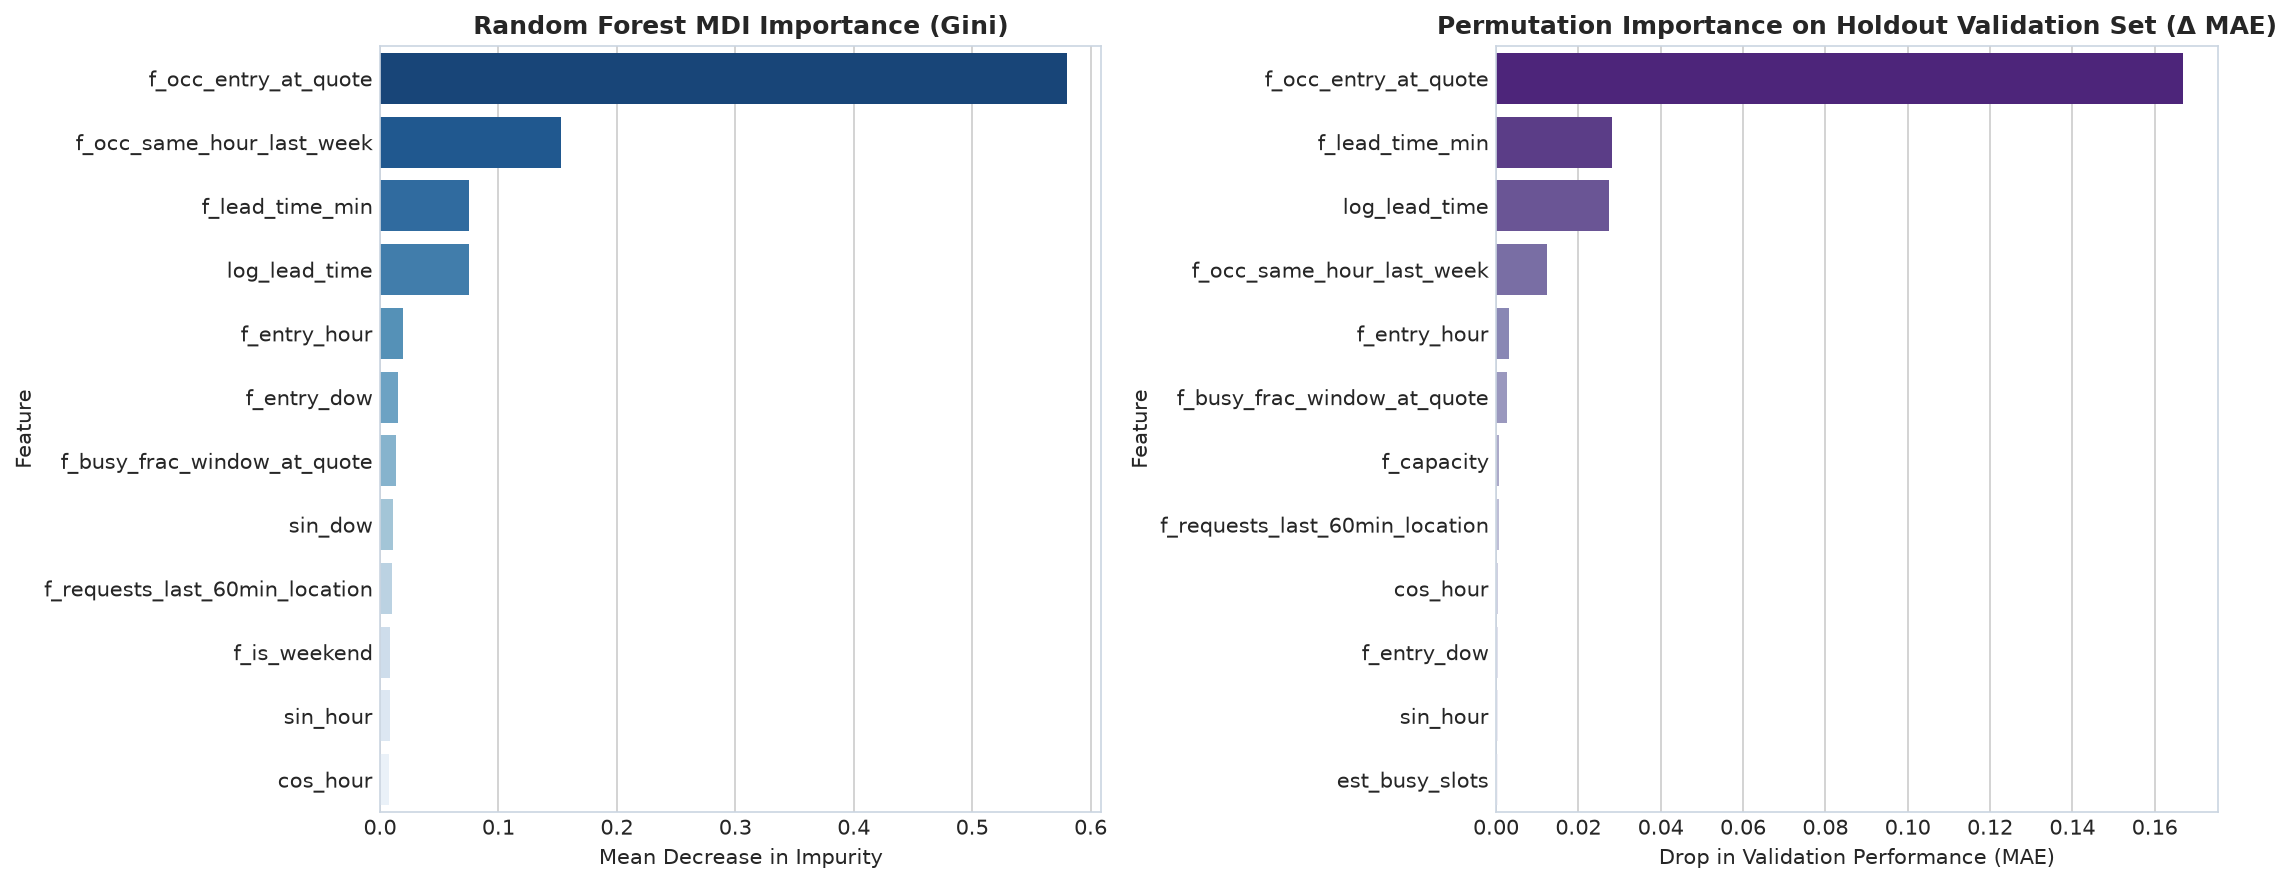

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: MDI Importance
sns.barplot(
    data=mdi_importance.head(12),
    x='MDI_Importance',
    y='Feature',
    palette='Blues_r',
    ax=ax1
)
ax1.set_title("Random Forest MDI Importance (Gini)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Mean Decrease in Impurity")

# Plot 2: Permutation Importance
sns.barplot(
    data=perm_df.head(12),
    x='Permutation_Importance_MAE',
    y='Feature',
    palette='Purples_r',
    ax=ax2
)
ax2.set_title("Permutation Importance on Holdout Validation Set (Δ MAE)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Drop in Validation Performance (MAE)")

plt.tight_layout()
fig5_path = os.path.join(FIG_DIR, "05_feature_importance_rf.png")
plt.savefig(fig5_path, dpi=300)
plt.show()

### Key Feature Selection Insights:
1. **Dominant Signal 1 (`f_occ_entry_at_quote` & `est_busy_slots`):** The existing occupancy locked at quote time accounts for the largest fraction of predictive signal.
2. **Dominant Signal 2 (`f_occ_same_hour_last_week`):** Weekly seasonality provides critical anchor information for advance bookings where current occupancy is still low.
3. **Temporal Signals (`sin_hour`, `cos_hour`, `f_entry_dow`):** Capture diurnal and weekend surge peaks.
4. **Recent Momentum (`f_requests_last_60min_location`):** Informs real-time arrival velocity.
5. **Decision:** All engineered features demonstrate positive permutation importance on the holdout set; no features degrade validation performance. All are retained for model comparison.